In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm
from datetime import datetime
import os
import h5py
from modules.func import LINEAR, TANH, RELU, LOGSIG
from modules.model import Whittington_Model,LA_model
from modules.batch import expand_one_hot_vector,reduct_pred

#download MNIST
from keras.datasets import mnist
(train_image, train_label), (test_image, test_label) = mnist.load_data()
train_image = train_image / 255.0
test_image  = test_image / 255.0

In [4]:
# number of trials
num_trial  = 2
# training settings
num_step   = 1*10**5    # number of steps
num_test   = 500        # number of test images per accuracy evaluation
num_loop_list   = [0, 10, 30, 50]         # number of inference loops
# model settings
x_dim      = [784,100, 10]  #number of cells per layer
num_batch  = 20             # batch size
test_trial = 40     #number of accuracy evaluations per trial

# learning rates
lr_x       = 10**(-0.9) # learning rate for x (inference rate)
lr_weight  = 10**(-1.6) # learning rate for the weights

# activation function
f = LINEAR #LINEAR, TANH, RELU, LOGSIG

# list
results = {}

for num_loop in num_loop_list:

    results[num_loop] = {
        "energy":   [],
        "accuracy": [],
        "cossim":   [],
    }

    for _tri in range(num_trial):   # repeat num_trial times

        # choose the model
        model = LA_model(x_dim, num_batch, lr_x, lr_weight, f) #Whittington, LA_model

        # reset the temporary lists
        energy_list_tmp = []
        accuracy_list_tmp = []
        cossim_list_tmp = []

        for step in tqdm(range(int((num_step)/num_batch))):                 # num_step samples in batches of num_batch
            idx    = np.random.randint(0, train_image.shape[0], num_batch)  # pick random MNIST images
            inputs = train_image[idx].reshape(num_batch , -1)               # assign the random images to inputs
            target = expand_one_hot_vector(train_label[idx],num_batch,x_dim[-1])    # convert labels to target vectors for the batch

            model.initialize_states()                   # reset activities
            model.update_x(inputs, target, num_loop)    # update x
            model.update_weight()                       # update w

            cossim_list_tmp.append(model.save_cossim())         #record the cosine similarity
            energy_list_tmp.append(model.calculate_energy())    #record the energy

            # evaluate test accuracy
            if (step + 1) % int((num_step)/num_batch/test_trial) == 0 or step == 0:
                cnt = 0
                for _test in range(int(num_test/num_batch)):
                    idx    = np.random.randint(0, test_image.shape[0], num_batch)
                    inputs = test_image[idx].reshape(num_batch , -1)
                    model.initialize_states()
                    pred_vec= model.predict(inputs)
                    pred_list = reduct_pred(pred_vec, num_batch, x_dim[-1])
                    cnt += np.count_nonzero(pred_list == test_label[idx])
                accuracy_list_tmp.append(cnt / num_test)

        # store results
        results[num_loop]["energy"].append(
            np.asarray(energy_list_tmp, dtype=np.float32)
        )
        results[num_loop]["accuracy"].append(
            np.asarray(accuracy_list_tmp, dtype=np.float32)
        )
        results[num_loop]["cossim"].append(
            np.asarray(cossim_list_tmp, dtype=np.float32)
        )
    results[num_loop]["energy"] = np.stack(results[num_loop]["energy"], axis=0)
    results[num_loop]["accuracy"] = np.stack(results[num_loop]["accuracy"], axis=0)
    results[num_loop]["cossim"] = np.stack(results[num_loop]["cossim"], axis=0)


100%|██████████| 5000/5000 [01:26<00:00, 58.04it/s]


## Save

In [11]:
# timestamp
timestamp = datetime.now().strftime("%Y%m%d%H%M%S")
filename = f"{num_trial}trial_{num_step}step_{timestamp}"

# Save
save_dir = "./change_loop_result"
os.makedirs(save_dir, exist_ok=True)

save_path = os.path.join(save_dir, f"result_{filename}.h5")

with h5py.File(save_path, "w") as f:

    for num_loop, metrics in results.items():
        grp_noise = f.create_group(f"{num_loop}")

        for metric_name, trials in metrics.items():
            grp_metric = grp_noise.create_group(metric_name)

            for i, arr in enumerate(trials):
                grp_metric.create_dataset(
                    f"trial_{i}",
                    data=arr,
                    compression="gzip"
                )


## Load

In [12]:
# Load
results = {}

file_name = f"result_{filename}.h5"
save_dir = "./change_loop_result"
load_path = os.path.join(save_dir, file_name)

with h5py.File(load_path, "r") as f:
    for key in sorted(f.keys()):
        results[key] = {}

        for metric in sorted(f[key].keys()):
            trials = [
                ds[:] for ds in f[key][metric].values()
            ]
            results[key][metric] = np.stack(trials, axis=0)

## Visualization

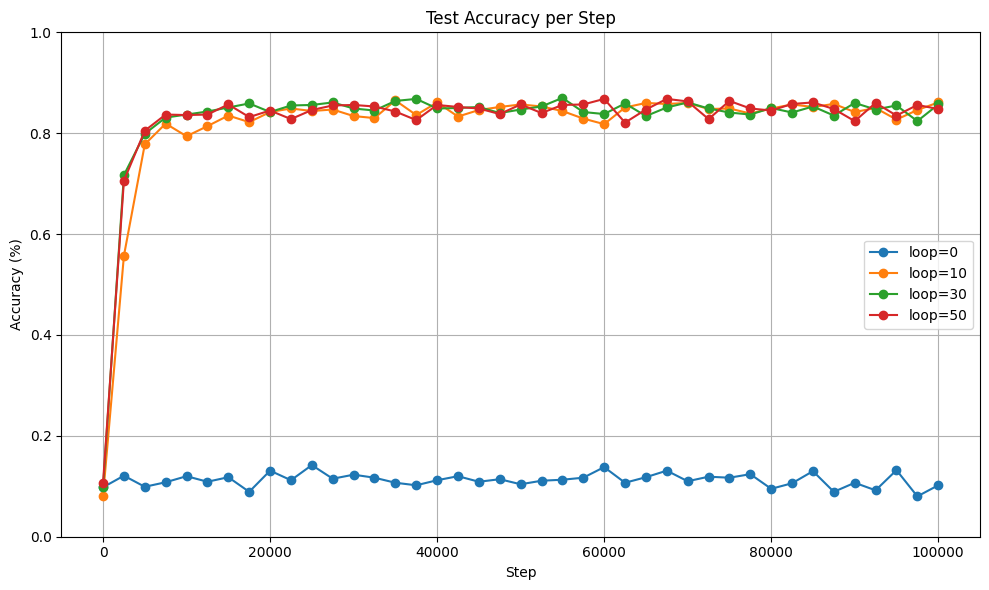

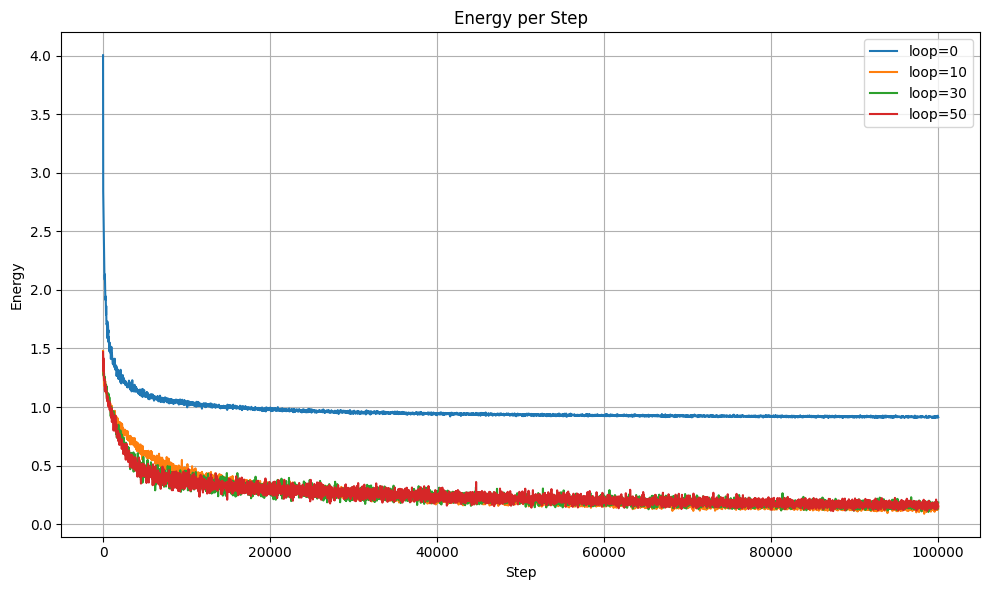

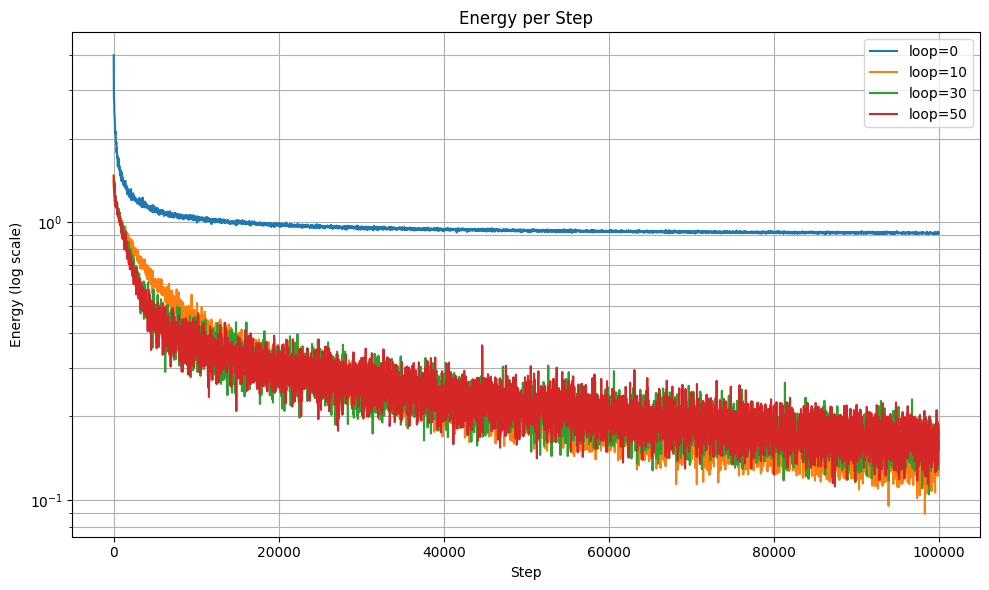

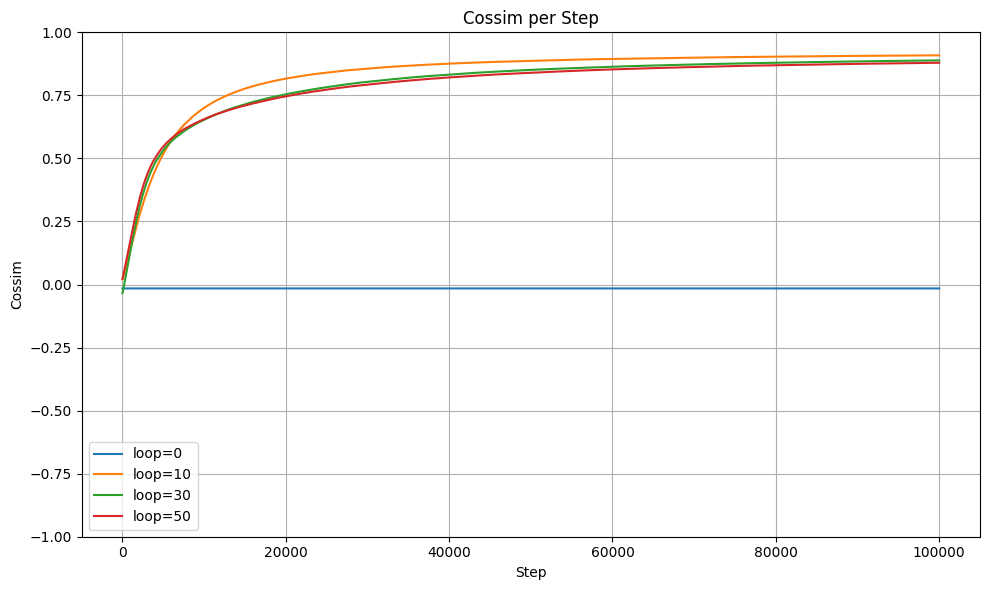

In [13]:
num_step = num_step

# Accuracy Plot
plt.figure(figsize=(10, 6))

for key in sorted(results.keys()):
    data = results[key]["accuracy"]
    data = data.mean(axis=0) 
    steps = np.linspace(0, num_step, len(data), endpoint=True)
    plt.plot(steps, data, label=f'loop={key}', marker='o')

plt.title('Test Accuracy per Step')
plt.xlabel('Step')
plt.ylabel('Accuracy (%)')
plt.ylim(0, 1)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# Energy Plot (Linear)
plt.figure(figsize=(10, 6))

for key in sorted(results.keys()):
    data = results[key]["energy"]
    data = data.mean(axis=0) 
    steps = np.linspace(0, num_step, len(data), endpoint=True)
    plt.plot(steps, data, label=f'loop={key}')

plt.title('Energy per Step')
plt.xlabel('Step')
plt.ylabel('Energy')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# Energy Plot (Log)
plt.figure(figsize=(10, 6))

for key in sorted(results.keys()):
    data = results[key]["energy"]
    data = data.mean(axis=0) 
    steps = np.linspace(0, num_step, len(data), endpoint=True)
    plt.plot(steps, data, label=f'loop={key}')

plt.yscale('log')
plt.title('Energy per Step')
plt.xlabel('Step')
plt.ylabel('Energy (log scale)')
plt.legend()
plt.grid(True, which='both')
plt.tight_layout()
plt.show()

# Angle Plot
plt.figure(figsize=(10, 6))

for key in sorted(results.keys()):
    data = results[key]["cossim"]
    data = data.mean(axis=0) 
    steps = np.linspace(0, num_step, len(data), endpoint=True)
    plt.plot(steps, data, label=f'loop={key}')

plt.ylim(-1, 1)
plt.title('Cossim per Step')
plt.xlabel('Step')
plt.ylabel('Cossim')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()
